# 01 — Single Sérsic perfect-data fitter validation

Question: if a noiseless, unconvolved Sérsic image is generated by `SersicModel`, does `DynestyFitter` recover the truth using the same model?


## Validation logic

This notebook is intentionally narrow. It tests one additional layer of complexity relative to the previous notebook. The goal is not to make a pretty demo; the goal is to know exactly where a discrepancy first appears.

BayMorph mask convention: `mask=True` means excluded pixel.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from baymorph.models import SersicModel
from baymorph.fitting.dynesty_generic import DynestyFitter
from baymorph.simulation.psf import GaussianPSF, convolve_with_psf
from baymorph.simulation.noise import add_gaussian_noise
from baymorph.plotting import corner_plot


def make_single_sersic_model(flux, re, n, q, theta, x0, y0):
    return SersicModel(
        flux=flux,
        re=re,
        n=n,
        q=q,
        theta=theta,
        x0=x0,
        y0=y0,
    )


def make_single_sersic_sky_model(flux, re, n, q, theta, x0, y0, sky):
    class SkyWrapper:
        def __init__(self, model, sky):
            self.model = model
            self.sky = sky
        def render(self, shape):
            return self.model.render(shape) + self.sky
    return SkyWrapper(make_single_sersic_model(flux, re, n, q, theta, x0, y0), sky)


def summarize_result(result, truth, *, angle_names=("theta",)):
    rows = []
    best = result.best_parameters
    median = result.median_parameters
    for name in result.parameter_names:
        true = truth.get(name, np.nan)
        med = median[name]
        ml = best[name]
        if name in angle_names:
            true_show = np.rad2deg(true)
            med_show = np.rad2deg(med)
            ml_show = np.rad2deg(ml)
            unit = "deg"
        else:
            true_show = true
            med_show = med
            ml_show = ml
            unit = ""
        rows.append({
            "parameter": name,
            "truth": true_show,
            "posterior_median": med_show,
            "maximum_likelihood": ml_show,
            "ML_minus_truth": ml_show - true_show,
            "unit": unit,
        })
    return pd.DataFrame(rows)


def image_diagnostics(data, model, noise=None, mask=None, title=""):
    residual = data - model
    if mask is None:
        valid = np.isfinite(data) & np.isfinite(model)
    else:
        valid = (~mask) & np.isfinite(data) & np.isfinite(model)
    stats = {
        "data_flux": float(np.nansum(data[valid])),
        "model_flux": float(np.nansum(model[valid])),
        "relative_flux_error": float((np.nansum(model[valid]) - np.nansum(data[valid])) / np.nansum(data[valid])),
        "max_abs_residual": float(np.nanmax(np.abs(residual[valid]))),
        "rms_residual": float(np.sqrt(np.nanmean(residual[valid] ** 2))),
    }
    if noise is not None:
        stats["chi2"] = float(np.nansum((residual[valid] / noise[valid]) ** 2))
        stats["reduced_chi2"] = float(stats["chi2"] / max(np.sum(valid), 1))
    display(pd.DataFrame([stats]).T.rename(columns={0: "value"}))

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, img, label in zip(axes, [data, model, residual], ["data", "ML model", "residual"]):
        im = ax.imshow(img, origin="lower")
        ax.set_title(label)
        plt.colorbar(im, ax=ax, fraction=0.046)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    return residual, stats


def radial_profile_plot(data, model, center, max_radius=45, mask=None):
    y, x = np.indices(data.shape)
    r = np.sqrt((x - center[0])**2 + (y - center[1])**2).astype(int)
    radii = np.arange(max_radius)
    data_prof, model_prof, resid_prof = [], [], []
    residual = data - model
    for rr in radii:
        ann = r == rr
        if mask is not None:
            ann &= ~mask
        data_prof.append(np.nanmedian(data[ann]))
        model_prof.append(np.nanmedian(model[ann]))
        resid_prof.append(np.nanmedian(residual[ann]))

    plt.figure(figsize=(6,4))
    plt.semilogy(radii, data_prof, "o", label="data")
    plt.semilogy(radii, model_prof, "-", label="ML model")
    plt.xlabel("radius [pix]")
    plt.ylabel("median intensity")
    plt.legend()
    plt.show()

    plt.figure(figsize=(6,3))
    plt.axhline(0.0, ls="--")
    plt.plot(radii, resid_prof)
    plt.xlabel("radius [pix]")
    plt.ylabel("median residual")
    plt.show()


,flux,re,n,q,theta_deg,x0,y0
0,100000.0,8.0,2.0,0.65,30.0,50.0,50.0


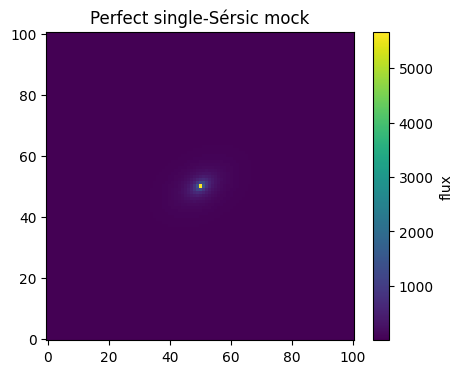

In [2]:

shape = (101, 101)
truth = {
    "flux": 1.0e5,
    "re": 8.0,
    "n": 2.0,
    "q": 0.65,
    "theta": np.deg2rad(30.0),
    "x0": 50.0,
    "y0": 50.0,
}

data = SersicModel(**truth).render(shape)
noise = np.ones(shape)  # likelihood scale only; no noise is injected
mask = np.zeros(shape, dtype=bool)

display(pd.DataFrame([{
    k: (np.rad2deg(v) if k == "theta" else v)
    for k, v in truth.items()
}]).rename(columns={"theta": "theta_deg"}))
plt.figure(figsize=(5,4))
plt.imshow(data, origin="lower")
plt.colorbar(label="flux")
plt.title("Perfect single-Sérsic mock")
plt.show()


In [3]:

parameter_names = ["flux", "re", "n", "q", "theta", "x0", "y0"]
prior_bounds = {
    "flux": (0.8e5, 1.2e5),
    "re": (5.0, 11.0),
    "n": (1.0, 3.5),
    "q": (0.45, 0.85),
    "theta": (-0.5*np.pi, 0.5*np.pi),
    "x0": (48.0, 52.0),
    "y0": (48.0, 52.0),
}

fitter = DynestyFitter(
    model_factory=make_single_sersic_model,
    data=data,
    noise=noise,
    parameter_names=parameter_names,
    prior_bounds=prior_bounds,
    mask=mask,
)
result = fitter.run(nlive=300, sample="rwalk", bound="multi", dlogz=0.05, seed=42, print_progress=True)


iter: 20666 | +300 | bound: 71 | nc: 1 | ncall: 538907 | eff(%):  3.893 | loglstar:   -inf < -9377.472 <    inf | logz: -9443.251 +/-  0.450 | dlogz:  0.000 >  0.050                                 

,parameter,truth,posterior_median,maximum_likelihood,ML_minus_truth,unit
0,flux,100000.00,100136.448279,100093.834605,93.834605,
1,re,8.00,8.019716,8.011935,0.011935,
2,n,2.00,2.006641,2.004425,0.004425,
3,q,0.65,0.649939,0.649954,-0.000046,
4,theta,30.00,29.981227,29.983551,-0.016449,deg
5,x0,50.00,50.000006,49.999995,-0.000005,
6,y0,50.00,50.000007,50.000013,0.000013,


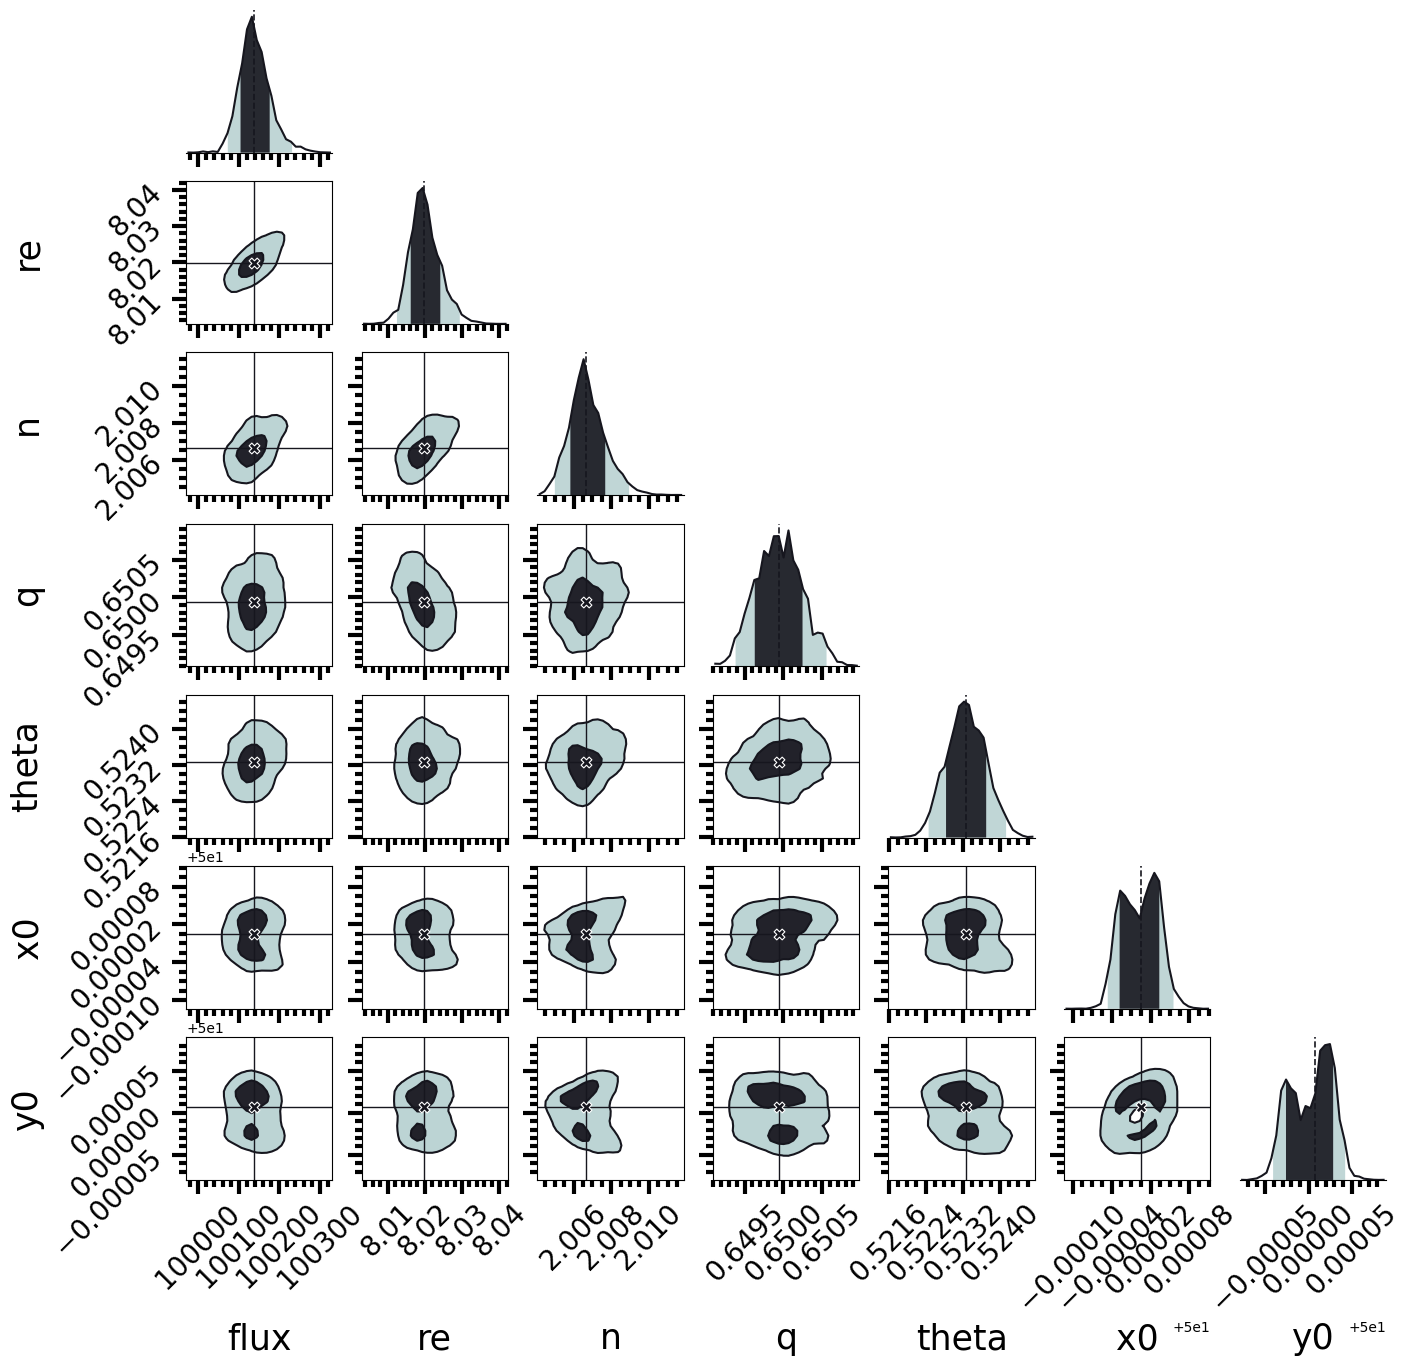

,value
data_flux,100000.000000
model_flux,100093.834605
relative_flux_error,0.000938
max_abs_residual,1.117777
rms_residual,0.025744
chi2,6.760673
reduced_chi2,0.000663


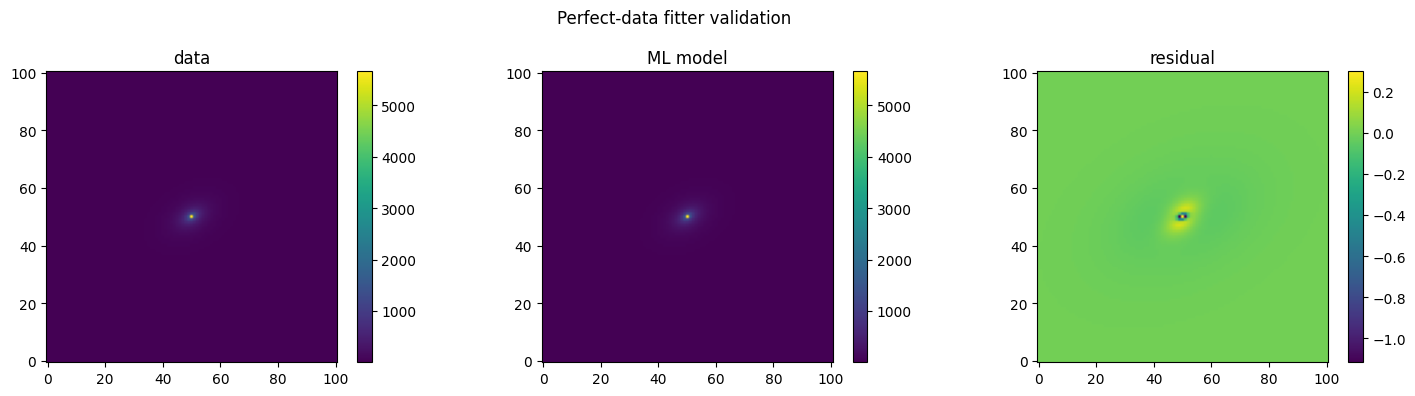

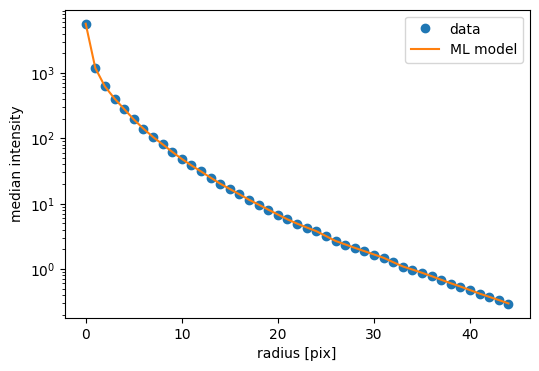

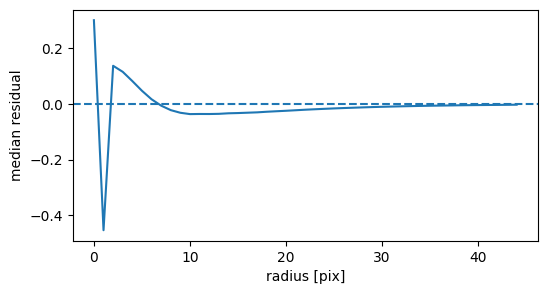

In [4]:

summary = summarize_result(result, truth)
display(summary)

fig, _, _ = corner_plot(result.posterior_samples.T, parameter_labels=parameter_names)
plt.show()

best_model = SersicModel(**result.best_parameters).render(shape)
residual, stats = image_diagnostics(data, best_model, noise=noise, mask=mask, title="Perfect-data fitter validation")
radial_profile_plot(data, best_model, center=(truth["x0"], truth["y0"]), mask=mask)

assert abs(result.best_parameters["flux"] - truth["flux"]) / truth["flux"] < 0.01
assert abs(result.best_parameters["re"] - truth["re"]) / truth["re"] < 0.03
assert abs(result.best_parameters["n"] - truth["n"]) / truth["n"] < 0.08
assert abs(result.best_parameters["q"] - truth["q"]) < 0.02
assert abs(result.best_parameters["theta"] - truth["theta"]) < np.deg2rad(1.0)
assert abs(result.best_parameters["x0"] - truth["x0"]) < 0.05
assert abs(result.best_parameters["y0"] - truth["y0"]) < 0.05
